Estimated focal length from known height: 2093.6 px (avg square size: 186.9 px)
Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).
Camera position in board frame (mm): X=112.8, Y=-235.7, Z=205.1
Height above board plane: 205.1 mm
Straight-line distance to board origin: 332.2 mm
Orientation (deg) - yaw: 4.7, pitch: -0.8, roll: 157.8

Camera is ~205.1 mm above the plane, tilted 22.3° from straight-down (nadir).
  (>5 deg off-nadir — the top-down mm/px scale from the plane calibration will be slightly less accurate away from the board's center.)
Saved camera pose calibration to camera_pose_calibration.npz


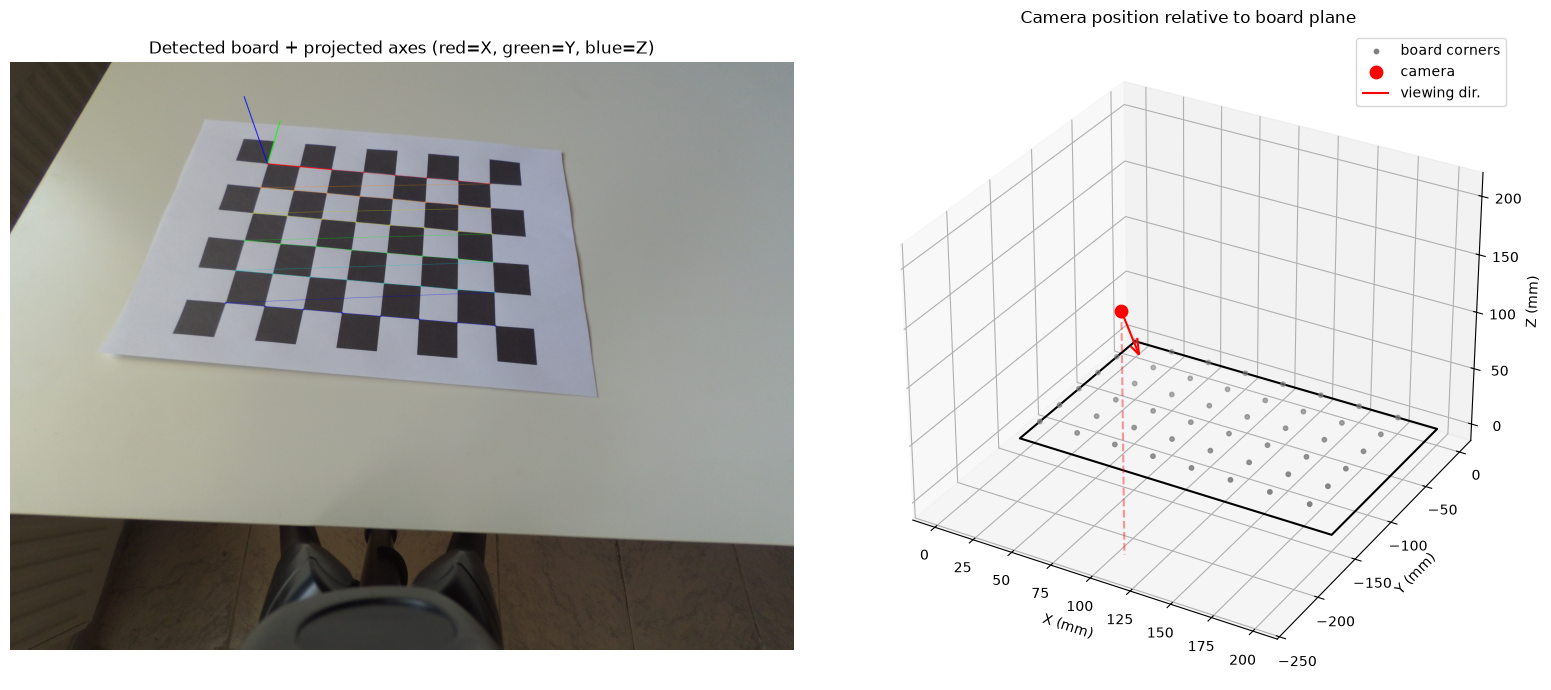

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3D projection)

IMAGE_PATH = "plate_plane.jpg"   # image WITH the full, unoccluded checkerboard

# Board spec: 8x6 SQUARES, 25 mm each. OpenCV wants INNER corners (squares - 1).
SQUARES_X, SQUARES_Y = 9, 7
SQUARE_SIZE_MM = 25.0
PATTERN_SIZE = (SQUARES_X - 1, SQUARES_Y - 1)  # (7, 5)

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

# --- Detect chessboard inner corners ---
ret, corners = cv2.findChessboardCorners(
    gray, PATTERN_SIZE,
    flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
)
if not ret:
    raise RuntimeError(
        f"Chessboard {PATTERN_SIZE} not found. Needs the full pattern visible/unoccluded."
    )
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)

# --- 3D object points on the board plane (z=0), in mm ---
objp = np.zeros((PATTERN_SIZE[0] * PATTERN_SIZE[1], 3), dtype=np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_SIZE[0], 0:PATTERN_SIZE[1]].T.reshape(-1, 2) * SQUARE_SIZE_MM

# --- Camera intrinsics ---
# solvePnP needs a camera matrix (focal length in pixels). A blind guess like
# fx=fy=image_width is often WRONG by a large factor for phone cameras (they
# tend to be wider-angle than that), which shows up as an overestimated
# distance/height — solvePnP scales the recovered depth roughly linearly with
# whatever focal length you feed it.
#
# Fix used here: measure the TRUE camera height once with a ruler/tape, then
# solve for the real focal length using the checkerboard's known 25mm squares
# and their apparent size in pixels (simple pinhole similar-triangles relation:
# focal_px = apparent_square_px * true_height_mm / SQUARE_SIZE_MM).
# This one manual measurement fixes the scale correctly for every future shot
# taken from this same fixed camera height/zoom — no extra calibration photos
# needed, and it's far more reliable than trying to self-calibrate focal
# length from vanishing points, which is numerically unstable for a
# near-overhead (near-fronto-parallel) view like this one.
#
# If you don't want to measure height, set KNOWN_HEIGHT_MM = None to fall
# back to the rough fx=fy=image_width guess (expect the resulting distance to
# be off, potentially by a large factor).
KNOWN_HEIGHT_MM = 280.0  # <-- measure your actual camera height and set this

if KNOWN_HEIGHT_MM is not None:
    grid = corners.reshape(PATTERN_SIZE[1], PATTERN_SIZE[0], 2)  # (rows, cols, 2)
    dx = np.linalg.norm(np.diff(grid, axis=1), axis=2).mean()  # px spacing along rows
    dy = np.linalg.norm(np.diff(grid, axis=0), axis=2).mean()  # px spacing along columns
    avg_square_px = (dx + dy) / 2
    focal_length_guess = avg_square_px * KNOWN_HEIGHT_MM / SQUARE_SIZE_MM
    print(f"Estimated focal length from known height: {focal_length_guess:.1f} px "
          f"(avg square size: {avg_square_px:.1f} px)")
else:
    focal_length_guess = w
    print("WARNING: no known height provided — using a rough fx=fy=image_width "
          "guess. Expect the estimated distance/height below to be inaccurate.")

camera_matrix = np.array([
    [focal_length_guess, 0, w / 2],
    [0, focal_length_guess, h / 2],
    [0, 0, 1]
], dtype=np.float64)
dist_coeffs = np.zeros(5)  # assume no lens distortion

# --- Solve for camera pose relative to the board ---
success, rvec, tvec = cv2.solvePnP(
    objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
)
if not success:
    raise RuntimeError("solvePnP failed to find a pose.")

R, _ = cv2.Rodrigues(rvec)  # rotation matrix, board-frame -> camera-frame

# Camera position expressed IN THE BOARD'S coordinate frame:
# a point at the camera origin (0,0,0 in camera space) maps back via
# world = R^T @ (cam - t)  =>  cam_position_in_board = -R^T @ t
camera_position = (-R.T @ tvec).flatten()

# --- Enforce Z=0 on the board plane, camera on the Z+ side ---
# findChessboardCorners doesn't guarantee which physical corner becomes the
# origin, so depending on where it starts numbering, the recovered board Z
# axis can end up pointing AWAY from the camera (negative height) even though
# the camera is physically above the board. If that happens, flip the board's
# Y-axis convention and re-solve — this doesn't change any real measurement,
# it just picks the coordinate convention where the camera sits at Z+.
flipped_y = False
if camera_position[2] < 0:
    objp[:, 1] *= -1
    success, rvec, tvec = cv2.solvePnP(
        objp, corners, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
    )
    R, _ = cv2.Rodrigues(rvec)
    camera_position = (-R.T @ tvec).flatten()
    flipped_y = True
    print("Board Y-axis was flipped so the camera ends up at Z+ (board plane stays Z=0).")

# Height above the plane is just the Z component (plane is z=0)
height_above_plane = camera_position[2]
distance_to_origin = np.linalg.norm(camera_position)

# --- Orientation as Euler angles (degrees), for intuition ---
sy = np.sqrt(R[0, 0] ** 2 + R[1, 0] ** 2)
pitch = np.degrees(np.arctan2(-R[2, 0], sy))
yaw = np.degrees(np.arctan2(R[1, 0], R[0, 0]))
roll = np.degrees(np.arctan2(R[2, 1], R[2, 2]))

print(f"Camera position in board frame (mm): "
      f"X={camera_position[0]:.1f}, Y={camera_position[1]:.1f}, Z={camera_position[2]:.1f}")
print(f"Height above board plane: {height_above_plane:.1f} mm")
print(f"Straight-line distance to board origin: {distance_to_origin:.1f} mm")
print(f"Orientation (deg) - yaw: {yaw:.1f}, pitch: {pitch:.1f}, roll: {roll:.1f}")

# --- Camera is mounted above the plane looking down: report tilt from nadir ---
# (nadir = pointing straight down at the plane, i.e. 0 deg = perfectly overhead)
cam_forward = R.T @ np.array([0, 0, 1])  # camera's optical axis, expressed in board frame
down_vec = np.array([0, 0, -np.sign(height_above_plane) if height_above_plane != 0 else -1])
cos_tilt = np.clip(np.dot(cam_forward, down_vec) / np.linalg.norm(cam_forward), -1, 1)
tilt_from_nadir = np.degrees(np.arccos(cos_tilt))

print(f"\nCamera is ~{abs(height_above_plane):.1f} mm above the plane, "
      f"tilted {tilt_from_nadir:.1f}\u00b0 from straight-down (nadir).")
if tilt_from_nadir > 5:
    print("  (>5 deg off-nadir — the top-down mm/px scale from the plane "
          "calibration will be slightly less accurate away from the board's center.)")

# --- Save the calibrated pose so it can be reused on other images taken from
# the same fixed camera position/angle (e.g. to locate objects on the plane
# in shots that don't have the checkerboard visible) ---
np.savez(
    "camera_pose_calibration.npz",
    camera_matrix=camera_matrix,
    dist_coeffs=dist_coeffs,
    rvec=rvec,
    tvec=tvec,
    R=R,
    camera_position=camera_position,
)
print("Saved camera pose calibration to camera_pose_calibration.npz")

# --- Draw the board's XYZ axes on the image, anchored at the board origin ---
vis = img.copy()
axis_len = 2 * SQUARE_SIZE_MM
cv2.drawFrameAxes(vis, camera_matrix, dist_coeffs, rvec, tvec, axis_len, 4)
cv2.drawChessboardCorners(vis, PATTERN_SIZE, corners, ret)

# --- 3D plot: board plane + camera position/orientation ---
fig = plt.figure(figsize=(16, 7))

ax2d = fig.add_subplot(1, 2, 1)
ax2d.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax2d.set_title("Detected board + projected axes (red=X, green=Y, blue=Z)")
ax2d.axis("off")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")

# board plane corners, for a visual rectangle (matches the flipped Y convention if applied)
board_w = (SQUARES_X - 1) * SQUARE_SIZE_MM
board_h = (SQUARES_Y - 1) * SQUARE_SIZE_MM
signed_h = -board_h if flipped_y else board_h
board_corners = np.array([
    [0, 0, 0], [board_w, 0, 0], [board_w, signed_h, 0], [0, signed_h, 0], [0, 0, 0]
])
ax3d.plot(board_corners[:, 0], board_corners[:, 1], board_corners[:, 2], "k-")
ax3d.scatter(objp[:, 0], objp[:, 1], objp[:, 2], c="gray", s=10, label="board corners")

ax3d.scatter(*camera_position, c="red", s=80, label="camera")
# camera's viewing direction (already computed above), drawn as a short arrow
ax3d.quiver(*camera_position, *(cam_forward * 50), color="red", label="viewing dir.")
# plumb line straight down from the camera to the plane, for the overhead setup
ax3d.plot(
    [camera_position[0], camera_position[0]],
    [camera_position[1], camera_position[1]],
    [camera_position[2], 0],
    "r--", alpha=0.4
)

ax3d.set_xlabel("X (mm)")
ax3d.set_ylabel("Y (mm)")
ax3d.set_zlabel("Z (mm)")
ax3d.set_title("Camera position relative to board plane")
ax3d.legend()

plt.tight_layout()
plt.show()

Original calibration:
[[2.09357764e+03 0.00000000e+00 2.30400000e+03]
 [0.00000000e+00 2.09357764e+03 1.72800000e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion:
[0. 0. 0. 0. 0.]
Image size: 4608 x 3456

Scaled camera matrix:
[[2.09357764e+03 0.00000000e+00 2.30400000e+03]
 [0.00000000e+00 2.09357764e+03 1.72800000e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Plate contour area: 448040.5 px²

Detected corners:
[[1585.  645.]
 [1576. 1102.]
 [2823. 1248.]
 [2848. 1020.]]

Ordered image points:
0: (1585.0, 645.0)
1: (1576.0, 1102.0)
2: (2823.0, 1248.0)
3: (2848.0, 1020.0)

PLATE POSE
X = -82.27 mm
Y = -123.62 mm
Z = 239.49 mm
Roll  = 14.51°
Pitch = 1.11°
Yaw   = 6.84°

Reprojection errors:
Corner 0: 2.37 px
Corner 1: 1.95 px
Corner 2: 7.13 px
Corner 3: 7.55 px
Mean reprojection error: 4.75 px


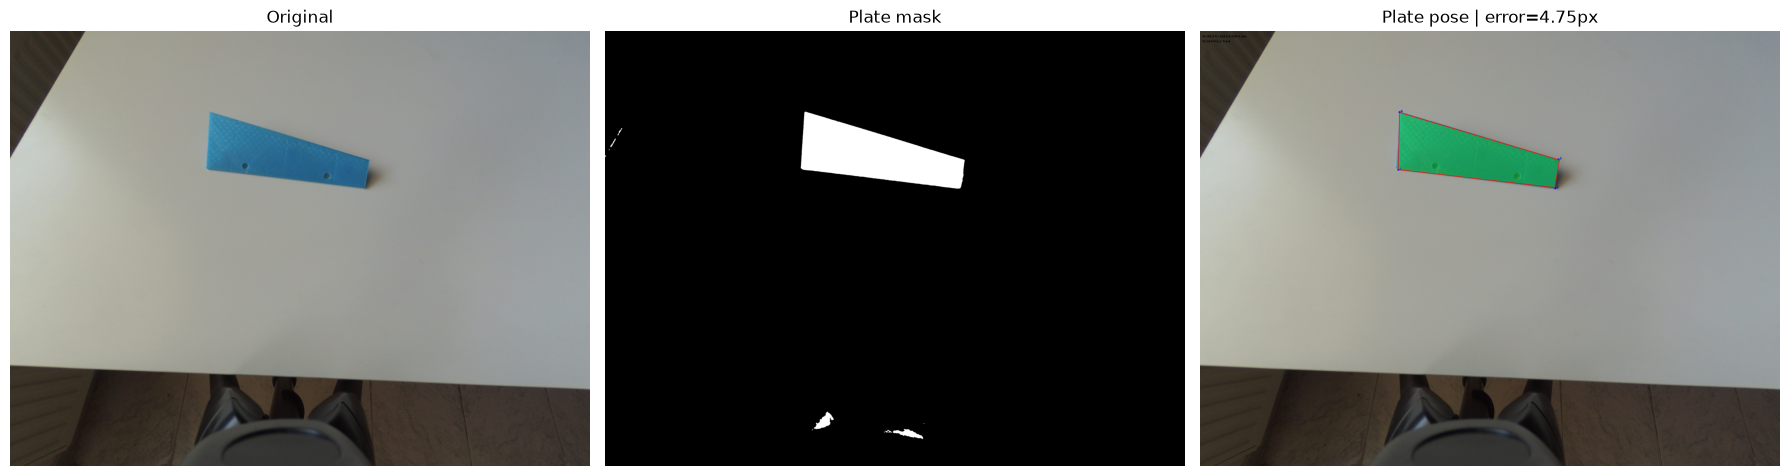

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from math import atan2, degrees


# =========================================================
# CONFIG
# =========================================================

CAMERA_CALIBRATION = "camera_pose_calibration.npz"

IMAGE_PATH = "plate_2.jpg"


# Plate3 dimensions
obj_pts = np.array([
    [0,   0,  0],
    [0,   50, 0],
    [150, 50, 0],
    [150, 25, 0],
], dtype=np.float32)


# =========================================================
# LOAD CALIBRATION
# =========================================================

data = np.load(CAMERA_CALIBRATION)

camera_matrix_original = data["camera_matrix"]
dist_coeffs = data["dist_coeffs"]

print("Original calibration:")
print(camera_matrix_original)

print("Distortion:")
print(dist_coeffs.ravel())


# =========================================================
# LOAD IMAGE
# =========================================================

frame = cv2.imread(IMAGE_PATH)

if frame is None:
    raise FileNotFoundError(IMAGE_PATH)

image_h, image_w = frame.shape[:2]

print(
    f"Image size: {image_w} x {image_h}"
)


# =========================================================
# SCALE CAMERA MATRIX
# =========================================================
#
# Calibration:
#       4608 x 3456
#
# Image:
#       2048 x 1536
#
# Therefore scale the intrinsic parameters.
#

calib_w = 4608
calib_h = 3456

sx = image_w / calib_w
sy = image_h / calib_h

camera_matrix = camera_matrix_original.copy()

camera_matrix[0, 0] *= sx       # fx
camera_matrix[0, 2] *= sx       # cx

camera_matrix[1, 1] *= sy       # fy
camera_matrix[1, 2] *= sy       # cy


print("\nScaled camera matrix:")
print(camera_matrix)


# =========================================================
# ROTATION MATRIX -> RPY
# =========================================================

def rotationMatrixToRPY(R):

    sy = np.sqrt(
        R[0, 0] ** 2 +
        R[1, 0] ** 2
    )

    singular = sy < 1e-6

    if not singular:

        x = atan2(
            R[2, 1],
            R[2, 2]
        )

        y = atan2(
            -R[2, 0],
            sy
        )

        z = atan2(
            R[1, 0],
            R[0, 0]
        )

    else:

        x = atan2(
            -R[1, 2],
            R[1, 1]
        )

        y = atan2(
            -R[2, 0],
            sy
        )

        z = 0

    return (
        degrees(x),
        degrees(y),
        degrees(z)
    )


# =========================================================
# DETECT BLUE PLATE
# =========================================================

hsv = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2HSV
)

# Blue color range
lower_blue = np.array([
    80, 40, 30
])

upper_blue = np.array([
    130, 255, 255
])

binary = cv2.inRange(
    hsv,
    lower_blue,
    upper_blue
)


# =========================================================
# CLEAN MASK
# =========================================================

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (5, 5)
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)


# =========================================================
# FIND CONTOURS
# =========================================================

contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError(
        "Plate was not detected."
    )


# Largest blue object
cnt = max(
    contours,
    key=cv2.contourArea
)


print(
    f"Plate contour area: "
    f"{cv2.contourArea(cnt):.1f} px²"
)


# =========================================================
# APPROXIMATE TO 4 CORNERS
# =========================================================

perimeter = cv2.arcLength(
    cnt,
    True
)

epsilon = 0.02 * perimeter

approx = cv2.approxPolyDP(
    cnt,
    epsilon,
    True
)


if len(approx) != 4:

    raise RuntimeError(
        f"Expected 4 plate corners, "
        f"got {len(approx)}."
    )


img_pts = approx.reshape(
    4, 2
).astype(np.float32)


print("\nDetected corners:")
print(img_pts)


# =========================================================
# ORDER CORNERS
# =========================================================
#
# We need:
#
# [0,0]      -> top-left
# [0,50]     -> bottom-left
# [150,50]   -> bottom-right
# [150,25]   -> top-right
#
# The contour in your image already naturally follows
# this order, but we make it explicit.
#

def order_plate_corners(points):

    points = np.asarray(
        points,
        dtype=np.float32
    )

    # top-left
    top_left = points[
        np.argmin(
            points[:, 0] + points[:, 1]
        )
    ]

    # bottom-right
    bottom_right = points[
        np.argmax(
            points[:, 0] + points[:, 1]
        )
    ]

    remaining = [
        p for p in points
        if not np.array_equal(p, top_left)
        and not np.array_equal(p, bottom_right)
    ]

    # Among remaining:
    # smaller x = bottom-left
    # larger x = top-right

    bottom_left = min(
        remaining,
        key=lambda p: p[0]
    )

    top_right = max(
        remaining,
        key=lambda p: p[0]
    )

    return np.array([
        top_left,
        bottom_left,
        bottom_right,
        top_right
    ], dtype=np.float32)


img_pts = order_plate_corners(
    img_pts
)


print("\nOrdered image points:")
for i, p in enumerate(img_pts):
    print(
        f"{i}: ({p[0]:.1f}, {p[1]:.1f})"
    )


# =========================================================
# SOLVE PNP
# =========================================================

success, rvec, tvec = cv2.solvePnP(
    objectPoints=obj_pts,
    imagePoints=img_pts,
    cameraMatrix=camera_matrix,
    distCoeffs=dist_coeffs,
    flags=cv2.SOLVEPNP_ITERATIVE
)


if not success:
    raise RuntimeError(
        "solvePnP failed."
    )


# =========================================================
# ROTATION
# =========================================================

R, _ = cv2.Rodrigues(
    rvec
)

roll, pitch, yaw = rotationMatrixToRPY(
    R
)


# =========================================================
# TRANSLATION
# =========================================================

tx, ty, tz = tvec.flatten()


print("\n==============================")
print("PLATE POSE")
print("==============================")

print(
    f"X = {tx:.2f} mm"
)

print(
    f"Y = {ty:.2f} mm"
)

print(
    f"Z = {tz:.2f} mm"
)

print(
    f"Roll  = {roll:.2f}°"
)

print(
    f"Pitch = {pitch:.2f}°"
)

print(
    f"Yaw   = {yaw:.2f}°"
)


# =========================================================
# REPROJECTION ERROR
# =========================================================

projected, _ = cv2.projectPoints(
    obj_pts,
    rvec,
    tvec,
    camera_matrix,
    dist_coeffs
)

projected = projected.reshape(
    -1, 2
)

errors = np.linalg.norm(
    projected - img_pts,
    axis=1
)

print("\nReprojection errors:")

for i, error in enumerate(errors):

    print(
        f"Corner {i}: "
        f"{error:.2f} px"
    )

print(
    f"Mean reprojection error: "
    f"{errors.mean():.2f} px"
)


# =========================================================
# VISUALIZATION
# =========================================================

processed = frame.copy()


# Draw detected corners

for i, p in enumerate(img_pts):

    x, y = p.astype(int)

    cv2.circle(
        processed,
        (x, y),
        8,
        (255, 0, 0),
        -1
    )

    cv2.putText(
        processed,
        str(i),
        (x + 10, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 0),
        2
    )


# =========================================================
# PROJECT PLATE
# =========================================================

projected_int = np.round(
    projected
).astype(np.int32)


# Fill projected plate

overlay = processed.copy()

cv2.fillPoly(
    overlay,
    [projected_int],
    (0, 255, 0)
)

processed = cv2.addWeighted(
    overlay,
    0.35,
    processed,
    0.65,
    0
)


# Draw projected outline

cv2.polylines(
    processed,
    [projected_int],
    True,
    (0, 0, 255),
    3
)


# =========================================================
# TEXT
# =========================================================

cv2.putText(
    processed,
    f"X={tx:.1f} Y={ty:.1f} Z={tz:.1f} mm",
    (20, 50),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    2
)

cv2.putText(
    processed,
    (
        f"R={roll:.1f} "
        f"P={pitch:.1f} "
        f"Y={yaw:.1f}"
    ),
    (20, 90),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    2
)


# =========================================================
# SHOW
# =========================================================

plt.figure(figsize=(18, 8))

plt.subplot(1, 3, 1)

plt.imshow(
    cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    binary,
    cmap="gray"
)

plt.title("Plate mask")

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    cv2.cvtColor(
        processed,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    f"Plate pose | error={errors.mean():.2f}px"
)

plt.axis("off")


plt.tight_layout()

plt.show()

Original calibration:
[[2.09357764e+03 0.00000000e+00 2.30400000e+03]
 [0.00000000e+00 2.09357764e+03 1.72800000e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion:
[0. 0. 0. 0. 0.]
Image size: 4608 x 3456

Scaled camera matrix:
[[2.09357764e+03 0.00000000e+00 2.30400000e+03]
 [0.00000000e+00 2.09357764e+03 1.72800000e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Plate contour area: 453115.0 px²

Detected corners:
[[2138.  993.]
 [2079. 1416.]
 [3423. 1604.]
 [3428. 1382.]]

Ordered image points:
0: (2138.0, 993.0)
1: (2079.0, 1416.0)
2: (3423.0, 1604.0)
3: (3428.0, 1382.0)

PLATE POSE
X = -18.47 mm
Y = -82.50 mm
Z = 234.80 mm
Roll  = -9.79°
Pitch = -2.31°
Yaw   = 7.42°

Reprojection errors:
Corner 0: 1.45 px
Corner 1: 2.02 px
Corner 2: 4.27 px
Corner 3: 3.84 px
Mean reprojection error: 2.89 px


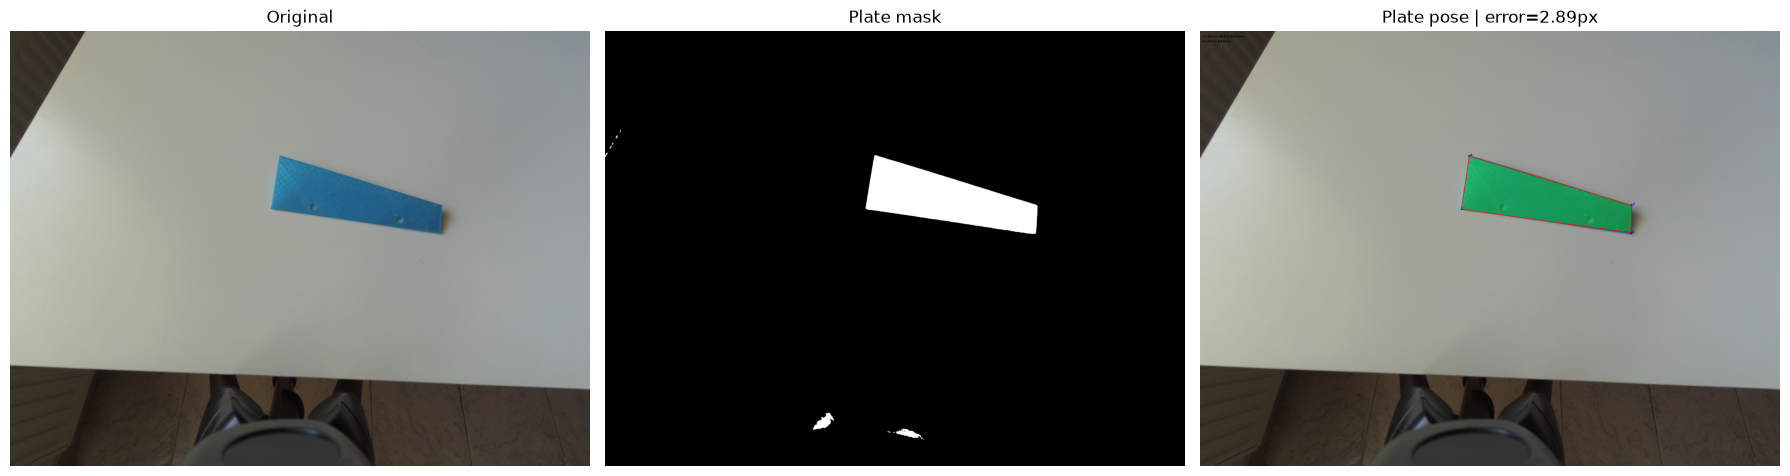

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from math import atan2, degrees


# =========================================================
# CONFIG
# =========================================================

CAMERA_CALIBRATION = "camera_pose_calibration.npz"

IMAGE_PATH = "plate_1.jpg"


# Plate3 dimensions
obj_pts = np.array([
    [0,   0,  0],
    [0,   50, 0],
    [150, 50, 0],
    [150, 25, 0],
], dtype=np.float32)


# =========================================================
# LOAD CALIBRATION
# =========================================================

data = np.load(CAMERA_CALIBRATION)

camera_matrix_original = data["camera_matrix"]
dist_coeffs = data["dist_coeffs"]

print("Original calibration:")
print(camera_matrix_original)

print("Distortion:")
print(dist_coeffs.ravel())


# =========================================================
# LOAD IMAGE
# =========================================================

frame = cv2.imread(IMAGE_PATH)

if frame is None:
    raise FileNotFoundError(IMAGE_PATH)

image_h, image_w = frame.shape[:2]

print(
    f"Image size: {image_w} x {image_h}"
)


# =========================================================
# SCALE CAMERA MATRIX
# =========================================================
#
# Calibration:
#       4608 x 3456
#
# Image:
#       2048 x 1536
#
# Therefore scale the intrinsic parameters.
#

calib_w = 4608
calib_h = 3456

sx = image_w / calib_w
sy = image_h / calib_h

camera_matrix = camera_matrix_original.copy()

camera_matrix[0, 0] *= sx       # fx
camera_matrix[0, 2] *= sx       # cx

camera_matrix[1, 1] *= sy       # fy
camera_matrix[1, 2] *= sy       # cy


print("\nScaled camera matrix:")
print(camera_matrix)


# =========================================================
# ROTATION MATRIX -> RPY
# =========================================================

def rotationMatrixToRPY(R):

    sy = np.sqrt(
        R[0, 0] ** 2 +
        R[1, 0] ** 2
    )

    singular = sy < 1e-6

    if not singular:

        x = atan2(
            R[2, 1],
            R[2, 2]
        )

        y = atan2(
            -R[2, 0],
            sy
        )

        z = atan2(
            R[1, 0],
            R[0, 0]
        )

    else:

        x = atan2(
            -R[1, 2],
            R[1, 1]
        )

        y = atan2(
            -R[2, 0],
            sy
        )

        z = 0

    return (
        degrees(x),
        degrees(y),
        degrees(z)
    )


# =========================================================
# DETECT BLUE PLATE
# =========================================================

hsv = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2HSV
)

# Blue color range
lower_blue = np.array([
    80, 40, 30
])

upper_blue = np.array([
    130, 255, 255
])

binary = cv2.inRange(
    hsv,
    lower_blue,
    upper_blue
)


# =========================================================
# CLEAN MASK
# =========================================================

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (5, 5)
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel
)

binary = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)


# =========================================================
# FIND CONTOURS
# =========================================================

contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError(
        "Plate was not detected."
    )


# Largest blue object
cnt = max(
    contours,
    key=cv2.contourArea
)


print(
    f"Plate contour area: "
    f"{cv2.contourArea(cnt):.1f} px²"
)


# =========================================================
# APPROXIMATE TO 4 CORNERS
# =========================================================

perimeter = cv2.arcLength(
    cnt,
    True
)

epsilon = 0.02 * perimeter

approx = cv2.approxPolyDP(
    cnt,
    epsilon,
    True
)


if len(approx) != 4:

    raise RuntimeError(
        f"Expected 4 plate corners, "
        f"got {len(approx)}."
    )


img_pts = approx.reshape(
    4, 2
).astype(np.float32)


print("\nDetected corners:")
print(img_pts)


# =========================================================
# ORDER CORNERS
# =========================================================
#
# We need:
#
# [0,0]      -> top-left
# [0,50]     -> bottom-left
# [150,50]   -> bottom-right
# [150,25]   -> top-right
#
# The contour in your image already naturally follows
# this order, but we make it explicit.
#

def order_plate_corners(points):

    points = np.asarray(
        points,
        dtype=np.float32
    )

    # top-left
    top_left = points[
        np.argmin(
            points[:, 0] + points[:, 1]
        )
    ]

    # bottom-right
    bottom_right = points[
        np.argmax(
            points[:, 0] + points[:, 1]
        )
    ]

    remaining = [
        p for p in points
        if not np.array_equal(p, top_left)
        and not np.array_equal(p, bottom_right)
    ]

    # Among remaining:
    # smaller x = bottom-left
    # larger x = top-right

    bottom_left = min(
        remaining,
        key=lambda p: p[0]
    )

    top_right = max(
        remaining,
        key=lambda p: p[0]
    )

    return np.array([
        top_left,
        bottom_left,
        bottom_right,
        top_right
    ], dtype=np.float32)


img_pts = order_plate_corners(
    img_pts
)


print("\nOrdered image points:")
for i, p in enumerate(img_pts):
    print(
        f"{i}: ({p[0]:.1f}, {p[1]:.1f})"
    )


# =========================================================
# SOLVE PNP
# =========================================================

success, rvec, tvec = cv2.solvePnP(
    objectPoints=obj_pts,
    imagePoints=img_pts,
    cameraMatrix=camera_matrix,
    distCoeffs=dist_coeffs,
    flags=cv2.SOLVEPNP_ITERATIVE
)


if not success:
    raise RuntimeError(
        "solvePnP failed."
    )


# =========================================================
# ROTATION
# =========================================================

R, _ = cv2.Rodrigues(
    rvec
)

roll, pitch, yaw = rotationMatrixToRPY(
    R
)


# =========================================================
# TRANSLATION
# =========================================================

tx, ty, tz = tvec.flatten()


print("\n==============================")
print("PLATE POSE")
print("==============================")

print(
    f"X = {tx:.2f} mm"
)

print(
    f"Y = {ty:.2f} mm"
)

print(
    f"Z = {tz:.2f} mm"
)

print(
    f"Roll  = {roll:.2f}°"
)

print(
    f"Pitch = {pitch:.2f}°"
)

print(
    f"Yaw   = {yaw:.2f}°"
)


# =========================================================
# REPROJECTION ERROR
# =========================================================

projected, _ = cv2.projectPoints(
    obj_pts,
    rvec,
    tvec,
    camera_matrix,
    dist_coeffs
)

projected = projected.reshape(
    -1, 2
)

errors = np.linalg.norm(
    projected - img_pts,
    axis=1
)

print("\nReprojection errors:")

for i, error in enumerate(errors):

    print(
        f"Corner {i}: "
        f"{error:.2f} px"
    )

print(
    f"Mean reprojection error: "
    f"{errors.mean():.2f} px"
)


# =========================================================
# VISUALIZATION
# =========================================================

processed = frame.copy()


# Draw detected corners

for i, p in enumerate(img_pts):

    x, y = p.astype(int)

    cv2.circle(
        processed,
        (x, y),
        8,
        (255, 0, 0),
        -1
    )

    cv2.putText(
        processed,
        str(i),
        (x + 10, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 0, 0),
        2
    )


# =========================================================
# PROJECT PLATE
# =========================================================

projected_int = np.round(
    projected
).astype(np.int32)


# Fill projected plate

overlay = processed.copy()

cv2.fillPoly(
    overlay,
    [projected_int],
    (0, 255, 0)
)

processed = cv2.addWeighted(
    overlay,
    0.35,
    processed,
    0.65,
    0
)


# Draw projected outline

cv2.polylines(
    processed,
    [projected_int],
    True,
    (0, 0, 255),
    3
)


# =========================================================
# TEXT
# =========================================================

cv2.putText(
    processed,
    f"X={tx:.1f} Y={ty:.1f} Z={tz:.1f} mm",
    (20, 50),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    2
)

cv2.putText(
    processed,
    (
        f"R={roll:.1f} "
        f"P={pitch:.1f} "
        f"Y={yaw:.1f}"
    ),
    (20, 90),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 0),
    2
)


# =========================================================
# SHOW
# =========================================================

plt.figure(figsize=(18, 8))

plt.subplot(1, 3, 1)

plt.imshow(
    cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    binary,
    cmap="gray"
)

plt.title("Plate mask")

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    cv2.cvtColor(
        processed,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    f"Plate pose | error={errors.mean():.2f}px"
)

plt.axis("off")


plt.tight_layout()

plt.show()